In [17]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

In [18]:
df = pd.read_csv("/content/Iris (2).csv")

In [19]:
X = df[['SepalLengthCm', 'SepalWidthCm',
        'PetalLengthCm', 'PetalWidthCm']]

y = df['Species']

In [20]:
le = LabelEncoder()
y = le.fit_transform(y)

In [21]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42)

In [22]:
lda = LinearDiscriminantAnalysis()
lda.fit(X_train, y_train)


LinearDiscriminantAnalysis()

In [23]:
y_pred = lda.predict(X_test)

In [24]:
print("Accuracy:", accuracy_score(y_test, y_pred))

Accuracy: 1.0


In [25]:
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))


Confusion Matrix:
[[10  0  0]
 [ 0  9  0]
 [ 0  0 11]]


In [26]:
print("\nClassification Report:")
print(classification_report(y_test, y_pred))


Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        10
           1       1.00      1.00      1.00         9
           2       1.00      1.00      1.00        11

    accuracy                           1.00        30
   macro avg       1.00      1.00      1.00        30
weighted avg       1.00      1.00      1.00        30



In [27]:
flower = pd.DataFrame(
    [[5.1, 3.5, 1.4, 0.2]],
    columns=X.columns
)

In [28]:
prediction = lda.predict(flower)

In [29]:
print("\nFlower belongs to:",
      le.inverse_transform(prediction)[0])


Flower belongs to: Iris-setosa


In [30]:
X_lda = lda.transform(X)

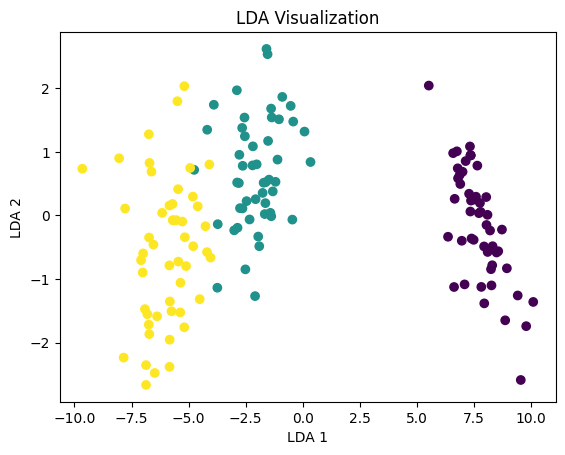

In [31]:
plt.scatter(X_lda[:, 0], X_lda[:, 1], c=y)
plt.xlabel("LDA 1")
plt.ylabel("LDA 2")
plt.title("LDA Visualization")
plt.show()